# Practice 10 — CNN Visualization

**Goal:** look inside a trained network in three ways.

| View | Question it answers |
|:---|:---|
| Grad-CAM | Which region of the image supports the predicted class? |
| Filter weights | What is the first convolution tuned to? |
| Feature maps | Where in the image does it respond? |

- Nothing is trained here → the weights arrive pretrained on ImageNet

---
## Step 0. Imports and Setup

- `grad-cam` (imported as `pytorch_grad_cam`) → installed by the first cell if it is missing
- `resnet18` with ImageNet weights; `eval()` → batch normalization uses its running statistics
- `preprocess` = the inference transform that goes with these weights (resize to 256, centre crop 224, normalize) → any other scaling changes the prediction

In [1]:
import subprocess
import sys

try:
    import pytorch_grad_cam
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'grad-cam'], check=True)
    import pytorch_grad_cam

print('grad-cam is available')

grad-cam is available


In [2]:
import os
import urllib.request

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms

np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device: {device}')

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).to(device)
model.eval()
imagenet_classes = models.ResNet18_Weights.DEFAULT.meta['categories']

# the statistics the pretrained weights were fitted under
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

device: cuda


---
## Step 1. A Photograph and Its Prediction

- Any image works → put another link from https://unsplash.com/ in `sample_url`

photograph: (2070, 1380) (width, height)


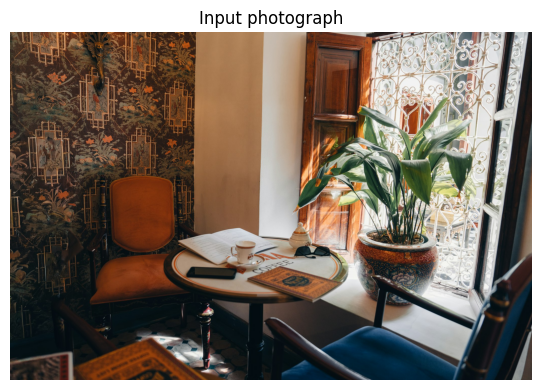

In [3]:
sample_url = ('https://images.unsplash.com/photo-1760681557777-bfac1f18cf90'
              '?ixlib=rb-4.1.0&auto=format&fit=crop&q=80&w=2070')
image_path = 'data/sample.jpg'
os.makedirs('data', exist_ok=True)
urllib.request.urlretrieve(sample_url, image_path)

image = Image.open(image_path).convert('RGB')
print(f'photograph: {image.size} (width, height)')

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(image)
ax.set_title('Input photograph')
ax.axis('off')
plt.tight_layout()
plt.show()

- `preprocess` → one `(1, 3, 224, 224)` tensor; 1000 logits → softmax → `topk(5)` gives the five largest probabilities and their class indices

In [4]:
image_tensor = preprocess(image).unsqueeze(0).to(device)
print(f'input tensor: {tuple(image_tensor.shape)}')

with torch.no_grad():
    logits = model(image_tensor)
probabilities = logits.softmax(dim=1)[0]
top5 = probabilities.topk(5)
top1_index = top5.indices[0].item()

print('Top-5 predictions')
for rank, class_index in enumerate(top5.indices.tolist(), start=1):
    name = imagenet_classes[class_index]
    print(f'{rank}. [{class_index:3d}] {name:<22s} {probabilities[class_index]:.4f}')

input tensor: (1, 3, 224, 224)
Top-5 predictions
1. [532] dining table           0.5135
2. [762] restaurant             0.0688
3. [799] sliding door           0.0472
4. [846] table lamp             0.0450
5. [526] desk                   0.0266


- `dining table` 0.51, next `restaurant` 0.07 → one clear answer for a cluttered scene

- The 224×224 centre crop the network saw → back from the normalized tensor to [0, 1] for display

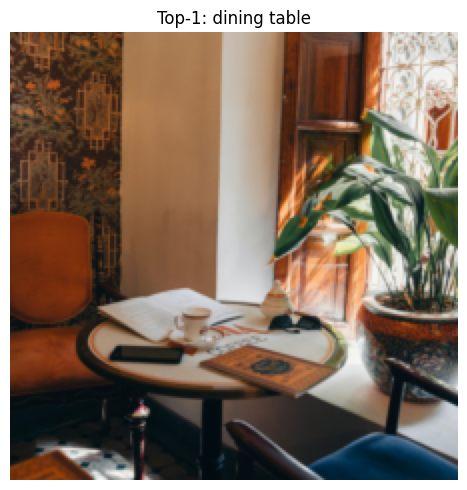

In [5]:
# turns the normalized (C, H, W) tensor back into an (H, W, C) array that imshow can display
image_rgb = image_tensor[0].permute(1, 2, 0).cpu().numpy()
image_rgb = image_rgb * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
image_rgb = np.clip(image_rgb, 0, 1).astype(np.float32)     # float32 in [0, 1], the form the overlay in Step 3 expects

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image_rgb)
ax.set_title(f'Top-1: {imagenet_classes[top1_index]}')
ax.axis('off')
plt.tight_layout()
plt.show()

---
## Step 2. The Target Layer

- Grad-CAM builds its map from one layer's output → that choice sets what the map can show
- `layer4[-1]` → the last residual block: 224 → 7 after five halvings, so a 7×7 map per channel, class-specific
- Earlier blocks → a finer grid, but features shared across classes

In [6]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [7]:
target_layer = model.layer4[-1]
print(target_layer)

BasicBlock(
  (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


---
## Step 3. Grad-CAM

$$\alpha^c_k = \frac{1}{Z}\sum_{i}\sum_{j}\frac{\partial y^c}{\partial A^k_{ij}},
\qquad
L^c = \mathrm{ReLU}\left(\sum_k \alpha^c_k A^k\right)$$

| Term | Meaning |
|:---|:---|
| $A^k$ | channel $k$ of the target layer's output, a 7×7 map |
| $y^c$ | logit of class $c$ |
| $\alpha^c_k$ | gradient of $y^c$ with respect to $A^k$ averaged over its $Z$ positions → one weight per channel |
| $L^c$ | weighted sum of the channels; $\mathrm{ReLU}$ keeps what supports the class |

- `ClassifierOutputTarget(class_index)` → $y^c$, the logit the gradients are taken from
- `GradCAM` returns $L^c$ resized from 7×7 to the 224×224 input and scaled to [0, 1] → `show_cam_on_image` blends it with the photograph

class [532] dining table


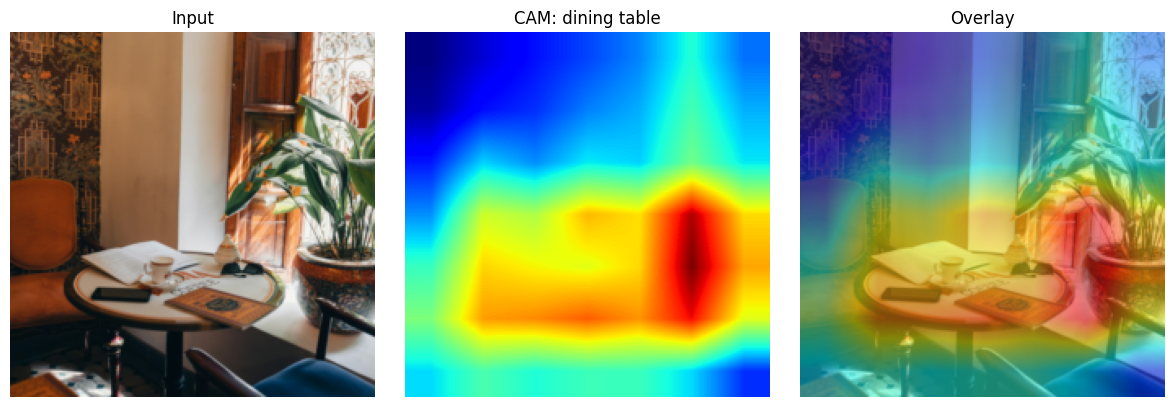

In [8]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

class_index = top1_index
print(f'class [{class_index:3d}] {imagenet_classes[class_index]}')

grad_cam = GradCAM(model=model, target_layers=[target_layer])
grayscale_cam = grad_cam(input_tensor=image_tensor,
                         targets=[ClassifierOutputTarget(class_index)])[0]   # [0]: the one image in the batch
overlay = show_cam_on_image(image_rgb, grayscale_cam, use_rgb=True)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image_rgb)
axes[0].set_title('Input')
axes[1].imshow(grayscale_cam, cmap='jet')
axes[1].set_title(f'CAM: {imagenet_classes[class_index]}')
axes[2].imshow(overlay)
axes[2].set_title('Overlay')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

- Heat over the table, strongest just right of it around the plant pot; the wall above stays cold → the evidence the network used for `dining table`

---
## Step 4. Filter Weights and Feature Maps

- `conv1` → 64 kernels of `3 × 7 × 7`, the first layer the photograph meets
- Filter weights → what each kernel is tuned to; feature maps → how strongly it fires at each position of this photograph

conv1 weights: (64, 3, 7, 7)


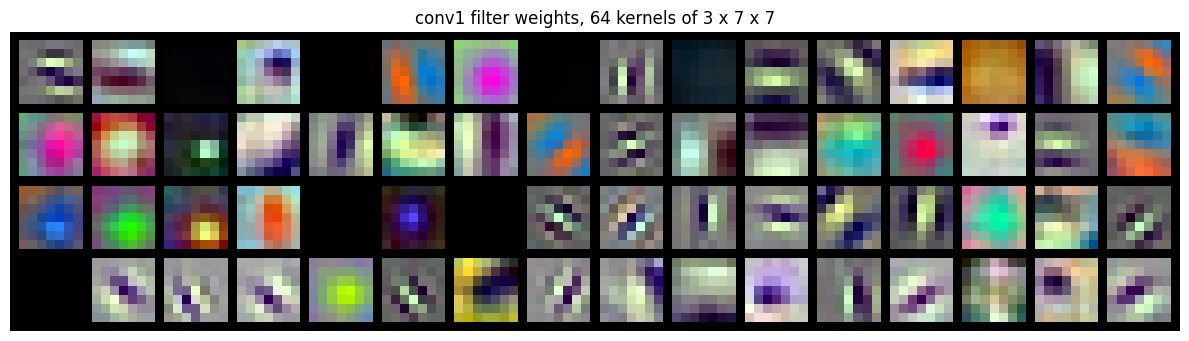

In [9]:
from torchvision.utils import make_grid

weights = model.conv1.weight.detach().cpu()        # (64, 3, 7, 7)
print(f'conv1 weights: {tuple(weights.shape)}')

grid = make_grid(weights, nrow=16, normalize=True, scale_each=True, padding=1)   # each kernel scaled to [0, 1] for display

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.imshow(grid.permute(1, 2, 0))
ax.set_title('conv1 filter weights, 64 kernels of 3 x 7 x 7')
ax.axis('off')
plt.tight_layout()
plt.show()

- Stripes of one orientation (Gabor-like: a sinusoid under a Gaussian window, the classic edge detector) and blobs of one colour against its opposite → what a first layer learns from ImageNet
- Black cells → kernels whose weights are all near zero, eight of the 64; the trained network does not use them

- Forward hook → copies a module's output during the forward pass
- Activation only, no gradient → what the layer responds to, not what supports the class

conv1 output: (64, 112, 112)


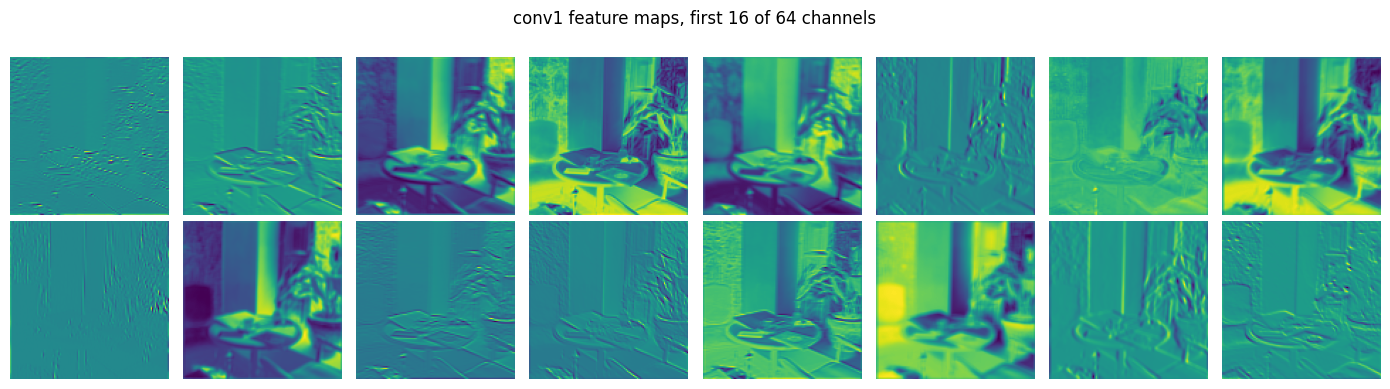

In [10]:
activations = []

def save_output(module, inputs, output):
    activations.append(output.detach().cpu())

hook = model.conv1.register_forward_hook(save_output)   # runs right after conv1 in every forward pass
with torch.no_grad():
    model(image_tensor)
hook.remove()

feature_maps = activations[0][0]                        # (64, 112, 112), one map per kernel
print(f'conv1 output: {tuple(feature_maps.shape)}')

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[i], cmap='viridis')          # imshow scales each map to its own range
    ax.axis('off')
fig.suptitle('conv1 feature maps, first 16 of 64 channels')
plt.tight_layout()
plt.show()

- Some channels respond to edges of one orientation, others to bright or dark regions → the photograph is still recognizable

---
## Summary

| View | Built from | Read at |
|:---|:---|:---|
| Grad-CAM | activations weighted by the gradient of one class | `layer4[-1]`, 7×7 |
| Filter weights | the learned kernels themselves | `conv1`, 64 of 3×7×7 |
| Feature maps | activations only | `conv1`, 112×112 |

- Grad-CAM → where the evidence for a class is; filters → what a layer is tuned to; feature maps → where it responds

---
## Exercises

1. Point `class_index` at another entry of `top5.indices` and rerun Step 3 — does the heat move with the class?
2. `target_layer = model.layer3[-1]` — the grid gets finer, but does the heat stay on the object?
3. Hook `model.layer4` instead of `conv1` — what is left of the photograph at that depth?

In [11]:
# Write your code here